Hipertensión


Aprendizaje Autómatico - CUN ACA 1


Integrantes del grupo:

Eyner Adrián Linares Lopez

Daniel Alejandro Roncancio Rodriguez

Oscar Mateo Tautiva Rozo

Karol Ginneth Tautiva Rozo

Docente: Hamilton Rivera

Fecha de entrega:

¿puede un modelo de Machine Learning ayudar a detectar a tiempo un problema de salud que muchas personas tienen sin saberlo?

El dataset utilizado proviene de la Encuesta Nacional de Salud y Nutrición de Estados Unidos (NHANES), que realiza el Centro para el Control y la Prevención de Enfermedades (CDC). Contiene información de 5.735 adultos entre 18 y 80 años y 28 variables por persona. Algo  clave es entender desde el inicio cómo se recogieron estos datos, porque no todos tienen la misma confiabilidad. Una parte proviene de una entrevista, donde la persona responde preguntas sobre su edad, sexo, nivel educativo, ingresos, consumo de alcohol y tabaco. Otra parte proviene de un examen físico realizado por personal entrenado en clínicas móviles, donde se midieron el peso, la estatura, la cintura y la presión arterial. En otras palabras, unos datos son lo que la persona *dice* y otros son lo que se *midió*.

Al explorar el dataset encontramos varios retos propios de una encuesta real. Las columnas tienen nombres en código (por ejemplo, `RIDAGEYR` es la edad y `BMXWAIST` la cintura), así que contruimos un diccionario de datos para entenderlas. Algunas respuestas usan números especiales como 7 o 9 para indicar "no sabe" o "no respondió", que no son valores reales y hay que limpiarlos. También muchos valores vacíos no son errores, sino preguntas que la encuesta solo le hacía a ciertas personas, como la educación, que solo se pregunta a mayores de 20 años. Entender esto fue fundamental para tomar buenas decisiones en la limpieza.

Investigando sobre el tema, la hipertensión es conocida como una enfermedad "silenciosa": muchas personas la tienen sin presentar síntomas, hasta que aparece una complicación grave. La forma de detectarla es medir la presión arterial, pero no todo el mundo lo hace con frecuencia. Allí se genera una oportunidad para la tecnología.

El objetivo de este estudio es construir un modelo de clasificación que estime si una persona adulta tiene la presión arterial elevada, usando únicamente datos sencillos de obtener: edad, sexo, peso, estatura, cintura, hábitos y condiciones socioeconómicas. Para definir qué es "presión elevada" se toma la referencia de la guía clínica ACC/AHA de 2017, que la establece en 130/80 mm Hg o más. Con ese criterio, aproximadamente el 40 % de las personas del dataset clasifica como presión elevada.


In [47]:
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')
ruta_archivo = '/content/drive/MyDrive/grafoca3d.csv'

df = pd.read_csv(ruta_archivo)
print(df.head())
print(df.info())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
    SEQN  ALQ101  ALQ110  ALQ130  SMQ020  RIAGENDR  RIDAGEYR  RIDRETH1  \
0  83732     1.0     NaN     1.0       1         1        62         3   
1  83733     1.0     NaN     6.0       1         1        53         3   
2  83734     1.0     NaN     NaN       1         1        78         3   
3  83735     2.0     1.0     1.0       2         2        56         3   
4  83736     2.0     1.0     1.0       2         2        42         4   

   DMDCITZN  DMDEDUC2  ...  BPXSY2  BPXDI2  BMXWT  BMXHT  BMXBMI  BMXLEG  \
0       1.0       5.0  ...   124.0    64.0   94.8  184.5    27.8    43.3   
1       2.0       3.0  ...   140.0    88.0   90.4  171.4    30.8    38.0   
2       1.0       3.0  ...   132.0    44.0   83.4  170.1    28.8    35.6   
3       1.0       5.0  ...   134.0    68.0  109.8  160.9    42.4    38.5   
4       1.0       4.0  ...   114.0    54.0   5

In [48]:
print(f"Duplicados: {df.duplicated().sum()}")

Duplicados: 0


In [49]:
print(f"Nulos: {df.isnull().sum()}")

Nulos: SEQN           0
ALQ101       527
ALQ110      4004
ALQ130      2356
SMQ020         0
RIAGENDR       0
RIDAGEYR       0
RIDRETH1       0
DMDCITZN       1
DMDEDUC2     261
DMDMARTL     261
DMDHHSIZ       0
WTINT2YR       0
SDMVPSU        0
SDMVSTRA       0
INDFMPIR     601
BPXSY1       334
BPXDI1       334
BPXSY2       200
BPXDI2       200
BMXWT         69
BMXHT         62
BMXBMI        73
BMXLEG       390
BMXARML      308
BMXARMC      308
BMXWAIST     367
HIQ210      1003
dtype: int64


vamos a trabajar sobre una copia del archivo original, lo primero es crear la variable objetivo, por tanto, debemos identificar las Diastolicas que no tienen medicion.

In [50]:
datos = df.copy()

for c in ["BPXDI1", "BPXDI2"]:
  datos.loc[datos[c] == 0, c] = np.nan

datos["sist_prom"] = datos[["BPXSY1", "BPXSY2"]].mean(axis=1)
datos["diast_prom"] = datos[["BPXDI1", "BPXDI2"]].mean(axis=1)

datos = datos.dropna(subset=["sist_prom", "diast_prom"])

datos["presion_elevada"] = ((datos["sist_prom"] >= 130) | (datos["diast_prom"] >= 80)).astype(int)

print(f"Total de Registros: {len(datos)}")

Total de Registros: 5550


Algunas columnas nos pasan información muy poco relevante, redundante, o que dependen de otra columna para saber si se aplica o no, por tanto, vamos a eliminarlas dejando aquellas que tienen conexión directa con la variante que se pretende hallar.

In [51]:
columnas_del = [
    "SEQN", "WTINT2YR", "SDMVPSU", "SDMVSTRA",              # identificador y diseño de la encuesta
    "BPXSY1", "BPXSY2", "BPXDI1", "BPXDI2",                 # fuga de datos
    "sist_prom", "diast_prom",                              # ya cumplieron su función
    "BMXWT", "BMXHT",                                       # redundantes con el IMC
    "ALQ110", "ALQ130", "HIQ210",                           # muchos nulos por diseño de la encuesta
    "BMXLEG", "BMXARML", "BMXARMC",                         # poco prácticas para la app
    "RIDRETH1", "DMDCITZN",
]

datos = datos.drop(columns=columnas_del)
print(datos.shape)

(5550, 11)


Como se nombraba anteriormente, valores como 7, 9, 77 no son datos reales y corresponden a información que no se pudo validar, por tanto, son reemplazados.

In [52]:
datos = datos.replace({
    "SMQ020":   {7: np.nan, 9: np.nan},
    "ALQ101":   {9: np.nan},
    "DMDEDUC2": {9: np.nan},
    "DMDMARTL": {77: np.nan},
})

datos.isna().sum()

,0
ALQ101,443
SMQ020,8
RIAGENDR,0
RIDAGEYR,0
DMDEDUC2,258
DMDMARTL,258
DMDHHSIZ,0
INDFMPIR,571
BMXBMI,56
BMXWAIST,296


Hasta este punto trabajamos con las columnas de forma original, pero, vamos a renombrarlas para que los resultados sean interpretados en Español.

In [53]:
# Renombrar: de códigos NHANES a nombres en español
nombres = {
    "RIDAGEYR": "edad", "RIAGENDR": "sexo", "BMXBMI": "imc", "BMXWAIST": "cintura_cm",
    "INDFMPIR": "ratio_ingreso_pobreza", "DMDHHSIZ": "personas_hogar",
    "SMQ020": "fuma", "ALQ101": "alcohol", "DMDEDUC2": "educacion", "DMDMARTL": "estado_civil",
}
datos = datos.rename(columns=nombres)

# pasar los códigos numéricos a etiquetas de texto
etiquetas = {
    "sexo": {1: "Hombre", 2: "Mujer"},
    "fuma": {1: "Sí", 2: "No"},
    "alcohol": {1: "Sí", 2: "No"},
    "educacion": {1: "Menos de 9.º grado", 2: "9.º a 11.º grado", 3: "Bachiller",
                  4: "Técnico o universidad incompleta", 5: "Universitario o más"},
    "estado_civil": {1: "Casado(a)", 2: "Viudo(a)", 3: "Divorciado(a)",
                     4: "Separado(a)", 5: "Soltero(a)", 6: "Unión libre"},
}
for col, mapa in etiquetas.items():
    datos[col] = datos[col].map(mapa)   # cualquier código fuera del mapa queda como NaN

# Menores de 20 no respondieron educación ni estado civil porque no les aplicaba
menor_20 = datos["edad"] < 20
for col in ["educacion", "estado_civil"]:
    datos.loc[menor_20 & datos[col].isna(), col] = "No aplica (menor de 20)"

# validación
for col in etiquetas:
    print(col, datos[col].value_counts(dropna=False).to_dict())
datos.head()

sexo {'Mujer': 2868, 'Hombre': 2682}
fuma {'No': 3288, 'Sí': 2254, nan: 8}
alcohol {'Sí': 3418, 'No': 1689, nan: 443}
educacion {'Técnico o universidad incompleta': 1573, 'Universitario o más': 1316, 'Bachiller': 1161, 'Menos de 9.º grado': 626, '9.º a 11.º grado': 616, 'No aplica (menor de 20)': 256, nan: 2}
estado_civil {'Casado(a)': 2704, 'Soltero(a)': 967, 'Divorciado(a)': 557, 'Unión libre': 505, 'Viudo(a)': 381, 'No aplica (menor de 20)': 256, 'Separado(a)': 178, nan: 2}


,alcohol,fuma,sexo,edad,educacion,estado_civil,personas_hogar,ratio_ingreso_pobreza,imc,cintura_cm,presion_elevada
0,Sí,Sí,Hombre,62,Universitario o más,Casado(a),2,4.39,27.8,101.1,0
1,Sí,Sí,Hombre,53,Bachiller,Divorciado(a),1,1.32,30.8,107.9,1
2,Sí,Sí,Hombre,78,Bachiller,Casado(a),2,1.51,28.8,116.5,1
3,No,No,Mujer,56,Universitario o más,Unión libre,1,5.00,42.4,110.1,1
4,No,No,Mujer,42,Técnico o universidad incompleta,Divorciado(a),5,1.23,20.3,80.4,0


Vamos a validar valores atipicos, lo hacemos por medio de boxplot, donde nos genera un rango de valores, y la concentracion de los datos, ademas los contamos con un criterio intercuarlitico, que lo que hace es entre el primer y tercer porcentil, se extiende un 1.5, los valores por fuera de ese rango se consideran atipicos, luego analizaremos esos atipicos para validar si corresponde a error de data o es la realidad.

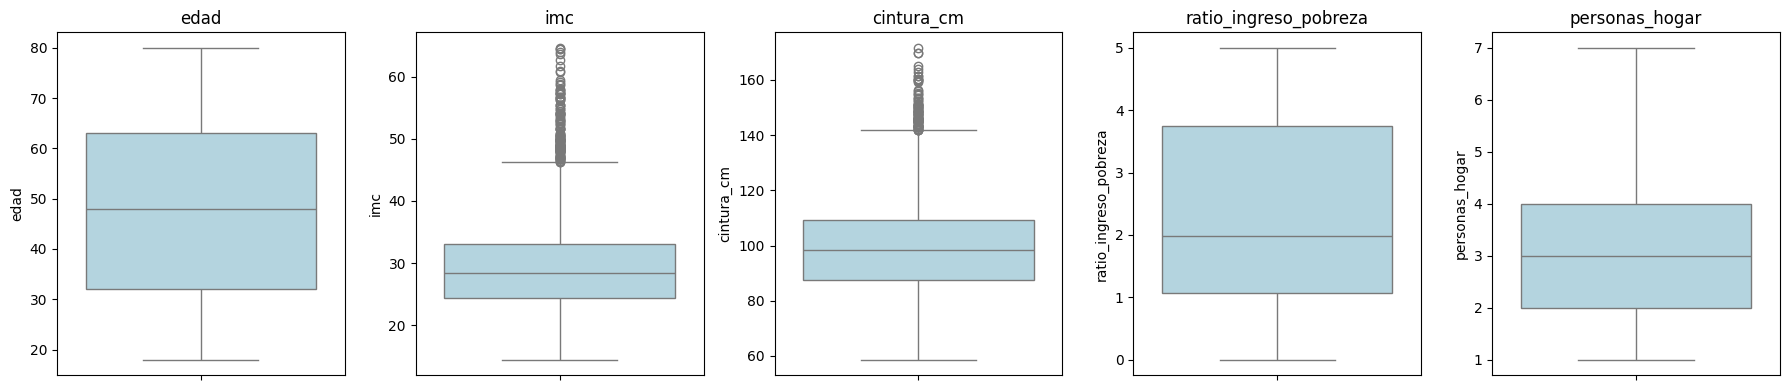

,variable,mínimo,máximo,límite inferior,límite superior,n atípicos,% atípicos
0,edad,18.0,80.0,-14.5,109.5,0,0.0
1,imc,14.5,64.6,11.2,46.3,142,2.6
2,cintura_cm,58.7,171.6,55.1,142.0,93,1.8
3,ratio_ingreso_pobreza,0.0,5.0,-3.0,7.8,0,0.0
4,personas_hogar,1.0,7.0,-1.0,7.0,0,0.0


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

numericas = ["edad", "imc", "cintura_cm", "ratio_ingreso_pobreza", "personas_hogar"]

# boxplot por variable
fig, ejes = plt.subplots(1, 5, figsize=(18, 4))
for eje, col in zip(ejes, numericas):
    sns.boxplot(y=datos[col], ax=eje, color="lightblue")
    eje.set_title(col)
plt.tight_layout()
plt.show()

# Contarlos con el criterio del rango intercuartílico (IQR)
resumen = []
for col in numericas:
    q1, q3 = datos[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((datos[col] < lim_inf) | (datos[col] > lim_sup)).sum()
    resumen.append({"variable": col, "mínimo": datos[col].min(), "máximo": datos[col].max(),
                    "límite inferior": round(lim_inf, 1), "límite superior": round(lim_sup, 1),
                    "n atípicos": n, "% atípicos": round(n / datos[col].notna().sum() * 100, 1)})
pd.DataFrame(resumen)

**Importante**: La persona con el IMC más alto (64,6) también tiene la cintura más grande (171,6 cm). Las dos mediciones son coherentes entre sí, lo que indica obesidad severa real y no un error de digitación.

como no se han imputado datos, por eso al calcular los atipicos tenemos en cuenta los NaN, para que el % sea calculado teniendo en cuenta estos valores.

**IMC y cintura:** los atípicos se conservan. Son casos reales de obesidad severa, y justamente es la población con más riesgo de presión alta. Si los eliminas, el modelo aprendería peor a reconocer a quienes más necesitan detección.
**Edad, ingreso y personas en el hogar:** no tienen atípicos, pero sí topes. Hay 329 personas con edad 80, 804 con ingreso 5 y 345 con 7 personas en el hogar. No se corrigen, porque no hay forma de saber el valor real, pero se mencionan como una limitación del dataset.

In [55]:
# ¿Los IMC más altos son coherentes con la cintura?
datos.sort_values("imc", ascending=False)[["edad", "sexo", "imc", "cintura_cm"]].head()

,edad,sexo,imc,cintura_cm
3537,24,Mujer,64.6,171.6
3598,46,Mujer,64.5,NaN
5331,51,Mujer,64.5,137.1
2097,25,Mujer,63.9,NaN
4804,72,Mujer,63.6,143.1


hacemos una revisión antes de iniciar con el entrenamiento, es normal ver datos nulos, ya que la imputacion la hacemos despues de la division para el entrenamiento.

In [56]:
print("Dimensiones:", datos.shape)          # esperado: (5550, 11)
print("\nTipos de dato:\n", datos.dtypes)
print("\nNulos restantes:\n", datos.isna().sum())
print("\nDistribución del objetivo:\n", datos["presion_elevada"].value_counts(normalize=True).round(3))

Dimensiones: (5550, 11)

Tipos de dato:
 alcohol                   object
fuma                      object
sexo                      object
edad                       int64
educacion                 object
estado_civil              object
personas_hogar             int64
ratio_ingreso_pobreza    float64
imc                      float64
cintura_cm               float64
presion_elevada            int64
dtype: object

Nulos restantes:
 alcohol                  443
fuma                       8
sexo                       0
edad                       0
educacion                  2
estado_civil               2
personas_hogar             0
ratio_ingreso_pobreza    571
imc                       56
cintura_cm               296
presion_elevada            0
dtype: int64

Distribución del objetivo:
 presion_elevada
0    0.601
1    0.399
Name: proportion, dtype: float64


In [57]:
X = datos.drop(columns="presion_elevada")
y = datos["presion_elevada"]

numericas = ["edad", "imc", "cintura_cm", "ratio_ingreso_pobreza", "personas_hogar"]
categoricas = ["sexo", "fuma", "alcohol", "educacion", "estado_civil"]

Dividimos los datos entre entramiento y prueba, 80 y 20 según las recomendaciones, ademas con Stratify ambos grupos tienen el mismo % de presion elevada.

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("% elevada -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Entrenamiento: (4440, 10) | Prueba: (1110, 10)
% elevada -> train: 0.399 | test: 0.399


hacemos la imputacion despues de dividir el entramiento y las pruebas para evitar fuga de datos.

empezamos con la imputación de datos.

In [59]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesador = ColumnTransformer([
    # Numéricas: primero escalar, luego imputar con los 5 vecinos más parecidos
    ("num", Pipeline([
        ("escalar", StandardScaler()),
        ("imputar", KNNImputer(n_neighbors=5)),
    ]), numericas),
    # Categóricas: los vacíos pasan a una categoría propia y luego a columnas 0/1
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="No responde")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categoricas),
])


In [60]:
X_train_transformado = preprocesador.fit_transform(X_train)
print("Forma:", X_train_transformado.shape)
print("Nulos después:", np.isnan(X_train_transformado).sum())



Forma: (4440, 28)
Nulos después: 0


In [61]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Regresión logística": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"modelo__C": [0.01, 0.1, 1, 10]},
    ),
    "Árbol de decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"modelo__max_depth": [3, 4, 5, 6, 8],
         "modelo__min_samples_leaf": [10, 30, 60]},
    ),
}

entrenados = {}
for nombre, (estimador, grilla) in modelos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", estimador)])
    busqueda = GridSearchCV(pipe, grilla, cv=cv, scoring="f1", n_jobs=-1)
    busqueda.fit(X_train, y_train)
    entrenados[nombre] = busqueda.best_estimator_
    print(f"{nombre}: {busqueda.best_params_} | F1 validación cruzada = {busqueda.best_score_:.3f}")

Regresión logística: {'modelo__C': 0.01} | F1 validación cruzada = 0.624
Árbol de decisión: {'modelo__max_depth': 4, 'modelo__min_samples_leaf': 60} | F1 validación cruzada = 0.644


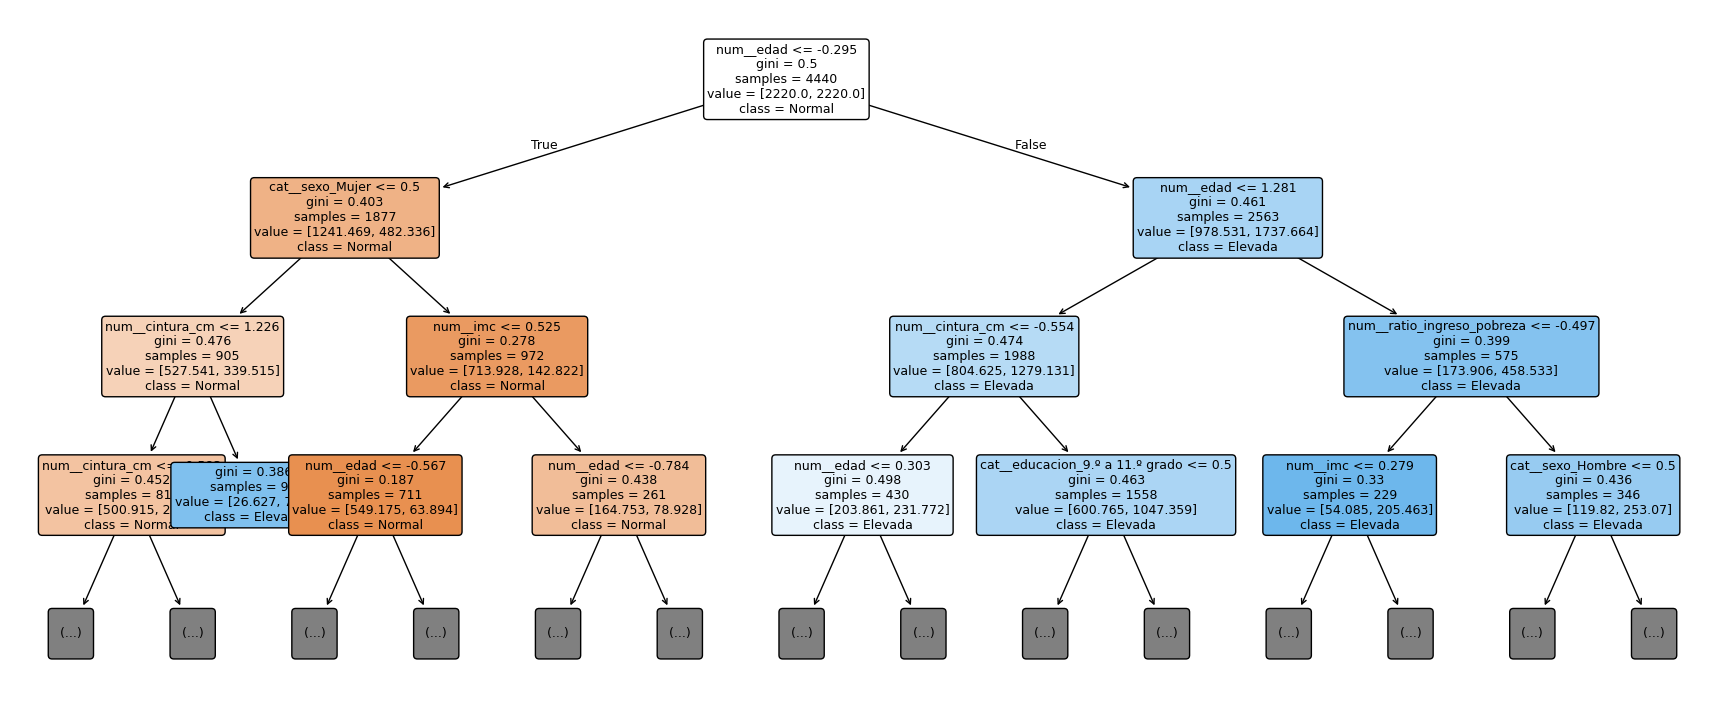

In [62]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

arbol = entrenados["Árbol de decisión"]
plt.figure(figsize=(22, 9))
plot_tree(arbol.named_steps["modelo"],
          feature_names=arbol.named_steps["prep"].get_feature_names_out(),
          class_names=["Normal", "Elevada"], filled=True, max_depth=3, fontsize=9, rounded=True)
plt.show()


In [63]:
from sklearn.metrics import accuracy_score

for nombre, modelo in entrenados.items():
    acc_tr = accuracy_score(y_train, modelo.predict(X_train))
    acc_te = accuracy_score(y_test, modelo.predict(X_test))
    print(f"{nombre}: entrenamiento {acc_tr:.3f} | prueba {acc_te:.3f} | diferencia {acc_tr - acc_te:.3f}")


Regresión logística: entrenamiento 0.673 | prueba 0.676 | diferencia -0.003
Árbol de decisión: entrenamiento 0.670 | prueba 0.660 | diferencia 0.010


In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def especificidad(y_real, y_pred):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred).ravel()
    return vn / (vn + fp)

filas = []
for nombre, modelo in entrenados.items():
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre,
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precisión": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "Especificidad": especificidad(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, prob)})
resultados = pd.DataFrame(filas).set_index("Modelo").round(3)
resultados

,Accuracy,Precisión,Recall,Especificidad,F1,ROC-AUC
Modelo,,,,,,
Regresión logística,0.676,0.576,0.713,0.651,0.637,0.749
Árbol de decisión,0.660,0.552,0.795,0.571,0.651,0.718


Los falsos negativos son el error que más nos preocupa: personas con presión alta a las que el modelo les diría "estás bien". El árbol se equivoca así con 91 personas y la regresión logística con 127. A cambio, el árbol genera 53 falsas alarmas más

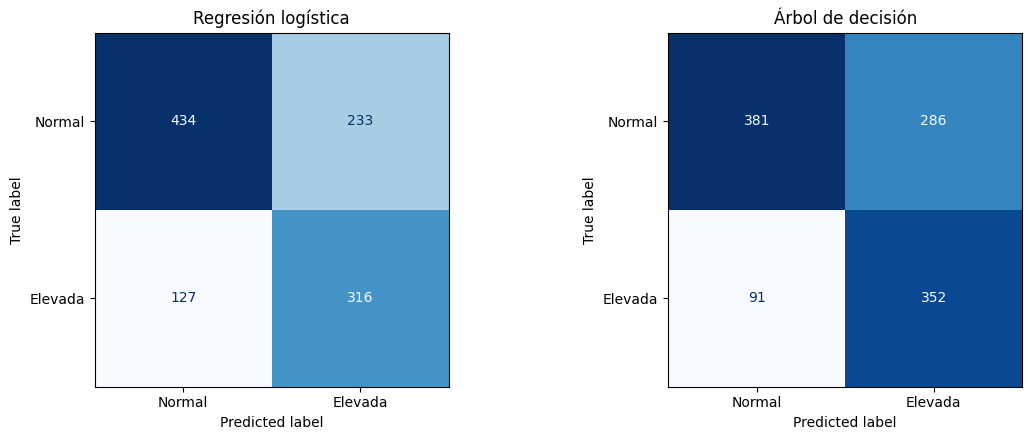

===== Regresión logística =====
              precision    recall  f1-score   support

      Normal       0.77      0.65      0.71       667
     Elevada       0.58      0.71      0.64       443

    accuracy                           0.68      1110
   macro avg       0.67      0.68      0.67      1110
weighted avg       0.69      0.68      0.68      1110

===== Árbol de decisión =====
              precision    recall  f1-score   support

      Normal       0.81      0.57      0.67       667
     Elevada       0.55      0.79      0.65       443

    accuracy                           0.66      1110
   macro avg       0.68      0.68      0.66      1110
weighted avg       0.71      0.66      0.66      1110



In [65]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, ejes = plt.subplots(1, len(entrenados), figsize=(6 * len(entrenados), 4.5))
for eje, (nombre, modelo) in zip(ejes, entrenados.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, display_labels=["Normal", "Elevada"],
                                          cmap="Blues", ax=eje, colorbar=False)
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

for nombre, modelo in entrenados.items():
    print(f"===== {nombre} =====")
    print(classification_report(y_test, modelo.predict(X_test), target_names=["Normal", "Elevada"]))

**Ajustamos un umbral**

Este es el hallazgo clave de la evaluación. Con un umbral de 0,40, la misma regresión logística:

Sube el recall de 0,713 a 0,885, superando también al árbol (0,795).
Reduce los falsos negativos de 127 a 51, menos que los 91 del árbol.
Logra el mejor F1 de todo el análisis (0,671).

El costo es que la especificidad baja a 0,50: más personas sanas recibirían la recomendación de medirse la presión. Para una herramienta de tamizaje es aceptable, porque una medición extra es barata y una hipertensión no detectada no lo es.


In [66]:
modelo_lr = entrenados["Regresión logística"]
prob = modelo_lr.predict_proba(X_test)[:, 1]

tabla = []
for umbral in [0.35, 0.40, 0.45, 0.50, 0.55]:
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    tabla.append({"Umbral": umbral, "Recall": recall_score(y_test, pred),
                  "Precisión": precision_score(y_test, pred),
                  "Especificidad": vn / (vn + fp), "F1": f1_score(y_test, pred),
                  "Falsos negativos": fn})
pd.DataFrame(tabla).round(3)

,Umbral,Recall,Precisión,Especificidad,F1,Falsos negativos
0,0.35,0.941,0.518,0.418,0.668,26
1,0.40,0.885,0.540,0.499,0.671,51
2,0.45,0.808,0.559,0.577,0.661,85
3,0.50,0.713,0.576,0.651,0.637,127
4,0.55,0.609,0.592,0.721,0.601,173


**Que aprendio cada modelo?**

Ambos modelos coinciden: la edad domina, seguida del sexo y las medidas de obesidad. Que dos modelos con lógicas tan distintas (uno lineal y otro basado en reglas) lleguen a la misma conclusión, y que esa conclusión coincida con lo que se sabe sobre hipertensión, indica que el modelo aprendió patrones reales y no ruido.

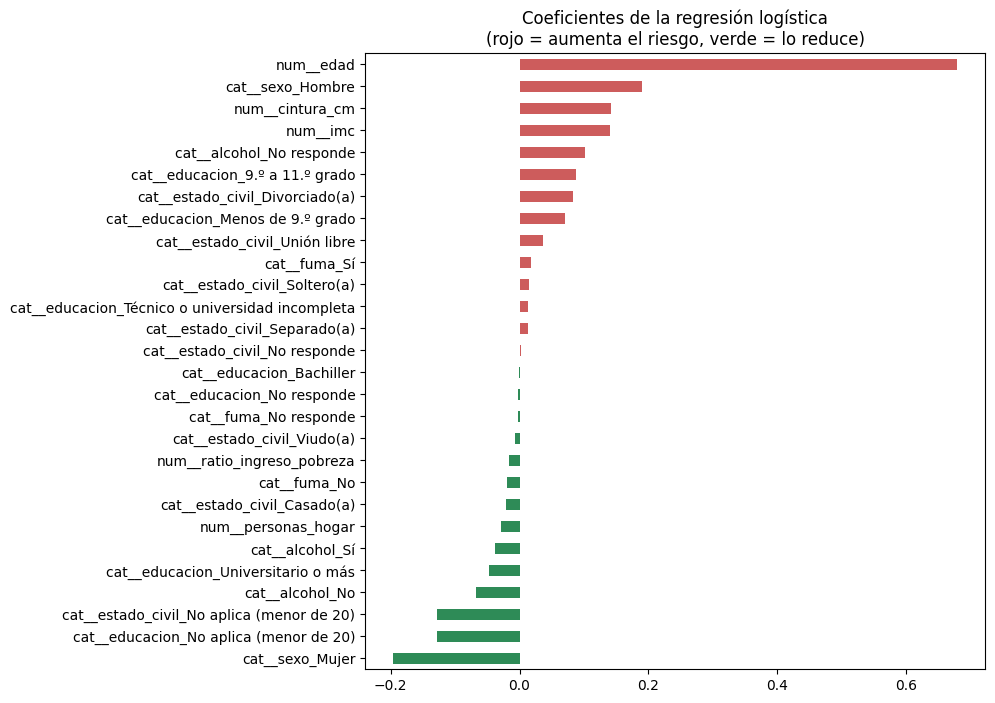

In [67]:
coef = pd.Series(modelo_lr.named_steps["modelo"].coef_[0],
                 index=modelo_lr.named_steps["prep"].get_feature_names_out()).sort_values()
plt.figure(figsize=(8, 8))
coef.plot(kind="barh", color=np.where(coef > 0, "indianred", "seagreen"))
plt.title("Coeficientes de la regresión logística\n(rojo = aumenta el riesgo, verde = lo reduce)")
plt.show()

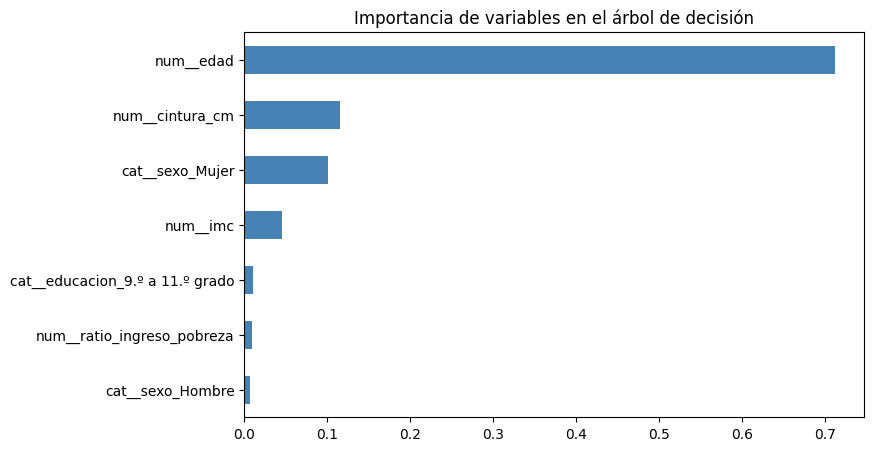

In [68]:
arbol = entrenados["Árbol de decisión"]
importancias = pd.Series(arbol.named_steps["modelo"].feature_importances_,
                         index=arbol.named_steps["prep"].get_feature_names_out())
importancias[importancias > 0].sort_values().plot(kind="barh", color="steelblue", figsize=(8, 5))
plt.title("Importancia de variables en el árbol de decisión")
plt.show()

Decisión final

Se selecciona la regresión logística con umbral de 0,40, por tres razones:

Con el umbral ajustado, logra el mejor recall (0,885) y el mejor F1 (0,671), superando al árbol en lo que más importa para el tamizaje.
Tiene el mejor AUC (0,749): ordena mejor el riesgo, y eso hace más confiable la probabilidad que verá el usuario en la app.
Es interpretable: puedes explicar cuánto pesa cada factor.

El árbol no se descarta del análisis: queda como modelo de comparación, y su diagrama es la herramienta ideal para explicar en el video cómo "razona" un modelo.

In [69]:
modelo_final = entrenados["Regresión logística"]
UMBRAL = 0.40

In [70]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, recall_score

# 1) Importancia por permutación: cuánto cae el AUC si se "desordena" cada variable
imp = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc",
                             n_repeats=20, random_state=42)
print(pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False).round(4))

# 2) Comparar modelo completo vs. modelo reducido
def evaluar(num, cat):
    prep = ColumnTransformer([
        ("num", Pipeline([("escalar", StandardScaler()), ("imputar", KNNImputer(n_neighbors=5))]), num),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="No responde")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    m = Pipeline([("prep", prep), ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced",
                  C=modelo_final.named_steps["modelo"].C))])
    m.fit(X_train[num + cat], y_train)
    p = m.predict_proba(X_test[num + cat])[:, 1]
    return round(roc_auc_score(y_test, p), 3), round(recall_score(y_test, (p >= UMBRAL).astype(int)), 3)

print("Completo :", evaluar(numericas, categoricas))
print("Reducido :", evaluar(["edad", "imc", "cintura_cm"], ["sexo"]))

edad                     0.1870
imc                      0.0079
sexo                     0.0075
cintura_cm               0.0046
alcohol                  0.0004
ratio_ingreso_pobreza    0.0000
estado_civil            -0.0001
educacion               -0.0001
personas_hogar          -0.0007
fuma                    -0.0010
dtype: float64
Completo : (np.float64(0.749), 0.885)
Reducido : (np.float64(0.751), 0.892)


In [71]:
from sklearn.model_selection import cross_val_score

def auc_cv(num, cat):
    prep = ColumnTransformer([
        ("num", Pipeline([("escalar", StandardScaler()), ("imputar", KNNImputer(n_neighbors=5))]), num),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="No responde")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    m = Pipeline([("prep", prep), ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced",
                  C=modelo_final.named_steps["modelo"].C))])
    s = cross_val_score(m, X_train[num + cat], y_train, cv=cv, scoring="roc_auc")
    return f"{s.mean():.3f} ± {s.std():.3f}"

print("Completo :", auc_cv(numericas, categoricas))
print("Reducido :", auc_cv(["edad", "imc", "cintura_cm"], ["sexo"]))

Completo : 0.726 ± 0.015
Reducido : 0.726 ± 0.014


**Conclusión**

Se compararon dos algoritmos clásicos de clasificación: la regresión logística y el árbol de decisión. Ambos alcanzaron un desempeño similar (accuracy de 0,66 a 0,68) sin evidencia de sobreajuste. Se seleccionó la regresión logística con un umbral de decisión de 0,40, priorizando la reducción de falsos negativos por tratarse de una herramienta de tamizaje en salud. El análisis de importancia por permutación mostró que la edad es el predictor dominante, seguida del IMC, el sexo y la circunferencia de cintura, mientras que las variables socioeconómicas y de hábitos no aportaron información. Por ello, el modelo final usa solo estas cuatro variables: obtiene un ROC-AUC de 0,726 en validación cruzada, igual al del modelo completo, y detecta el 89 % de los casos de presión elevada en el conjunto de prueba (recall de 0,892). El resultado es un modelo más simple, igual de preciso y más fácil de usar en la aplicación.

In [72]:

# EXPORTACIÓN DE ARCHIVOS PARA LA APP STREAMLIT

import json, joblib, zipfile
from sklearn.tree import plot_tree

# 1) Modelo final reducido (4 variables)
num_final, cat_final = ["edad", "imc", "cintura_cm"], ["sexo"]
prep_final = ColumnTransformer([
    ("num", Pipeline([("escalar", StandardScaler()), ("imputar", KNNImputer(n_neighbors=5))]), num_final),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="No responde")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_final)])
modelo_final = Pipeline([("prep", prep_final),
                         ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced",
                                   C=entrenados["Regresión logística"].named_steps["modelo"].C))])
modelo_final.fit(X_train[num_final + cat_final], y_train)

joblib.dump({"modelo": modelo_final, "umbral": UMBRAL,
             "variables": num_final + cat_final}, "modelo_presion.pkl")

#  Árbol de decisión (modelo de comparación, 10 variables)
joblib.dump(entrenados["Árbol de decisión"], "modelo_arbol.pkl")

#  Información del modelo
info = {"umbral": UMBRAL, "variables": num_final + cat_final,
        "opciones": {"educacion": sorted(datos["educacion"].dropna().unique().tolist()),
                     "estado_civil": sorted(datos["estado_civil"].dropna().unique().tolist())}}
with open("info_modelo.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

# Datos limpios (para la página de EDA)
datos.to_csv("datos_limpios.csv", index=False)

#  Probabilidades en el conjunto de prueba (para la página de evaluación)
pd.DataFrame({
    "real": y_test.values,
    "prob_logistica": modelo_final.predict_proba(X_test[num_final + cat_final])[:, 1],
    "prob_arbol": entrenados["Árbol de decisión"].predict_proba(X_test)[:, 1],
}).to_csv("resultados_prueba.csv", index=False)

#  Comparación KNN vs. mediana para la cintura faltante (datos de entrenamiento)
num_pipe = preprocesador.named_transformers_["num"]          # ya ajustado con X_train
imputado = num_pipe.named_steps["escalar"].inverse_transform(num_pipe.transform(X_train[numericas]))
imputado = pd.DataFrame(imputado, columns=numericas, index=X_train.index)
faltantes = X_train["cintura_cm"].isna()
pd.DataFrame({
    "imc": X_train.loc[faltantes, "imc"],
    "cintura_knn": imputado.loc[faltantes, "cintura_cm"],
    "cintura_mediana": X_train["cintura_cm"].median(),
}).to_csv("comparacion_knn.csv", index=False)

#  Imagen del árbol de decisión
arbol = entrenados["Árbol de decisión"]
plt.figure(figsize=(22, 9))
plot_tree(arbol.named_steps["modelo"], feature_names=arbol.named_steps["prep"].get_feature_names_out(),
          class_names=["Normal", "Elevada"], filled=True, max_depth=3, fontsize=9, rounded=True)
plt.savefig("arbol_decision.png", dpi=150, bbox_inches="tight")
plt.close()

# Empaquetar y descargar (Colab)
archivos = ["modelo_presion.pkl", "modelo_arbol.pkl", "info_modelo.json", "datos_limpios.csv",
            "resultados_prueba.csv", "comparacion_knn.csv", "arbol_decision.png"]
with zipfile.ZipFile("archivos_app.zip", "w") as z:
    for a in archivos:
        z.write(a)
print("Archivos generados:", archivos)

from google.colab import files
files.download("archivos_app.zip")

Archivos generados: ['modelo_presion.pkl', 'modelo_arbol.pkl', 'info_modelo.json', 'datos_limpios.csv', 'resultados_prueba.csv', 'comparacion_knn.csv', 'arbol_decision.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>